<a href="https://colab.research.google.com/github/Yvonne-dev80/ores5160-2026/blob/main/week11/week11assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
#Q1: Reading the CSV
#1.1 Opens the CSV with Python’s built-in csv module and prints the first 5 rows

import csv

with open("est2018-pop-res.csv", newline="") as f:
    reader = csv.reader(f)
    for i, row in enumerate(reader):
        if i == 5:
            break
        print(row)



['SUMLEV', 'REGION', 'DIVISION', 'STATE', 'NAME', 'POPESTIMATE2018', 'POPEST18PLUS2018', 'PCNT_POPEST18PLUS']
['010', '0', '0', '00', 'United States', '327167434', '253768092', '77.6']
['040', '3', '6', '01', 'Alabama', '4887871', '3798031', '77.7']
['040', '4', '9', '02', 'Alaska', '737438', '553622', '75.1']
['040', '4', '8', '04', 'Arizona', '7171646', '5528989', '77.1']


In [5]:
#1.2 Loading the same file into a pandas DataFrame, then printing its size (rows × columns) and its column names.

import pandas as pd

df = pd.read_csv("est2018-pop-res.csv", dtype={"REGION": str, "DIVISION": str})
print("Shape:", df.shape)
print("Columns:", list(df.columns))

Shape: (53, 8)
Columns: ['SUMLEV', 'REGION', 'DIVISION', 'STATE', 'NAME', 'POPESTIMATE2018', 'POPEST18PLUS2018', 'PCNT_POPEST18PLUS']


In [6]:
#1.3 Which column represents total population? Display the top 5 most populous states
#Removes the “United States” total row, then ranks the states by POPESTIMATE2018 (the total population column) to get the top 5
states = df[df["SUMLEV"] != 10]   # drop the "United States" total row
states.nlargest(5, "POPESTIMATE2018")[["NAME", "POPESTIMATE2018"]]

,NAME,POPESTIMATE2018
5,California,39557045
44,Texas,28701845
10,Florida,21299325
33,New York,19542209
39,Pennsylvania,12807060


In [7]:
#Q2: Basic statistical analysis
#2.1$2 Calculates the average state population, then adds up the population for each region to find the largest one.

avg = states["POPESTIMATE2018"].mean()
print(f"Average population: {avg:,.0f}")

region_names = {"1": "Northeast", "2": "Midwest", "3": "South", "4": "West", "X": "Puerto Rico"}
states = states.copy()
states["REGION_NAME"] = states["REGION"].map(region_names)

by_region = states.groupby("REGION_NAME")["POPESTIMATE2018"].sum().sort_values(ascending=False)
print(by_region)
print("Highest region:", by_region.idxmax())




Average population: 6,353,127
REGION_NAME
South          124753948
West            77993663
Midwest         68308744
Northeast       56111079
Puerto Rico      3195153
Name: POPESTIMATE2018, dtype: int64
Highest region: South


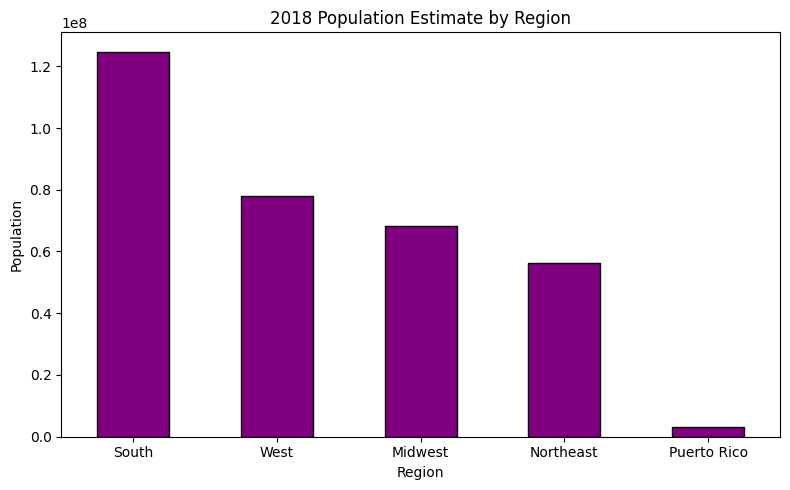

In [11]:
# a bar chart showing the population by region with matplotlib

import matplotlib.pyplot as plt

by_region.plot(kind="bar", color="purple", edgecolor="black", figsize=(8, 5))
plt.title("2018 Population Estimate by Region")
plt.xlabel("Region")
plt.ylabel("Population")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [9]:
#Q3: Parsing the JSON
#3.1 Loading the patient file into a Python dictionary
#3.2 print the official name, gender, birth date, and the city, state and postal code.

import json

with open("patient.json", encoding="utf-8") as f:
    patient = json.load(f)

official = next(n for n in patient["name"] if n["use"] == "official")
print("Name:", " ".join(official["given"]), official["family"])
print("Gender:", patient["gender"], "| Birth date:", patient["birthDate"])

addr = patient["address"][0]
print("Address:", addr["city"], addr["state"], addr["postalCode"])

Name: Peter James Chalmers
Gender: male | Birth date: 1974-12-25
Address: PleasantVille Vic 3999


In [10]:
#3.3 Picks out the phone entries from the contact list, counts them, and prints each type (work, mobile, old) with its number.

phones = [t for t in patient["telecom"] if t.get("system") == "phone"]
print("Number of phones:", len(phones))
for p in phones:
    print("-", p["use"], p["value"])



Number of phones: 3
- work (03) 5555 6473
- mobile (03) 3410 5613
- old (03) 5555 8834
